# Deep Learning Project: Infix to Postfix Notation Translation

**Author:** Matteo Cardellini
**Matricola:** 1186864
**Date:** January 14, 2026

## Project Description
The purpose of this project is to implement a neural network that performs the translation of mathematical formulae from traditional **infix notation**—where the operator appears between two operands—to **postfix** (also known as Reverse Polish Notation), where the operator follows the operands.

Infix notation is the most commonly used in human-readable mathematics (e.g., a + b), but it is inherently ambiguous without additional syntactic aids such as parentheses or operator precedence rules. This ambiguity arises because different parse trees can correspond to the same expression depending on how operations are grouped.

In contrast, postfix notation eliminates the need for parentheses entirely. The order of operations is explicitly encoded by the position of the operators relative to the operands, making it more suitable for stack-based evaluation and easier to parse programmatically.

**Example:**

Consider the ambiguous infix expression:
a + b * c

This expression can be parsed in at least two different ways:

Interpretation (Infix):	(a + b) * c	   
Equivalent Postfix: ab+c*

Interpretation (Infix):	a + (b * c)	          
Equivalent Postfix: abc*+


This project aims to learn such disambiguations and generate the correct postfix form from a given infix expression using a data-driven approach based on neural networks.

To simplify the task and control the complexity of expressions, we restrict our dataset to formulae with a maximum syntactic depth of 4. This means that the abstract syntax trees representing these expressions will have at most three levels, ensuring that the neural network operates on a bounded and manageable set of possible structures.

In [ ]:
!pip install keras==3.13 # install specific Keras version for Colab execution

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
import os
import gdown
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

<local-project>/.venv/lib/python3.13/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


We build formulae using 6 identifiers a,b,c,d,e,f and 4 binary operators +,-,*,/.
For simplicity we do not take advantage of precedence or associativity rules for infix notation, and suppose that all binary operations as always fully parenthesizes: (e1 op e2).

In [2]:
# -------------------- Constants --------------------
OPERATORS = ['+', '-', '*', '/']
IDENTIFIERS = list('abcdef')
SPECIAL_TOKENS = ['PAD', 'SOS', 'EOS']
SYMBOLS = ['(', ')', '+', '-', '*', '/']
VOCAB = SPECIAL_TOKENS + SYMBOLS + IDENTIFIERS + ['JUNK'] #may use junk in autoregressive generation

token_to_id = {tok: i for i, tok in enumerate(VOCAB)}
id_to_token = {i: tok for tok, i in token_to_id.items()}
VOCAB_SIZE = len(VOCAB)
PAD_ID = token_to_id['PAD']
EOS_ID = token_to_id['EOS']
SOS_ID = token_to_id['SOS']

MAX_DEPTH = 4
MAX_LEN = 4*2**MAX_DEPTH -2 #enough to fit expressions at given depth (+ EOS)

In [3]:
# -------------------- Expression Generation --------------------
def generate_infix_expression(max_depth):
    if max_depth == 0:
        return random.choice(IDENTIFIERS)
    elif random.random() < 0.25:
        return generate_infix_expression(max_depth - 1)
    else:
        left = generate_infix_expression(max_depth - 1)
        right = generate_infix_expression(max_depth - 1)
        op = random.choice(OPERATORS)
        return f'({left} {op} {right})'

def tokenize(expr):
    return [c for c in expr if c in token_to_id]

def infix_to_postfix(tokens):
    precedence = {'+': 1, '-': 1, '*': 2, '/': 2}
    output, stack = [], []
    for token in tokens:
        if token in IDENTIFIERS:
            output.append(token)
        elif token in OPERATORS:
            while stack and stack[-1] in OPERATORS and precedence[stack[-1]] >= precedence[token]:
                output.append(stack.pop())
            stack.append(token)
        elif token == '(':
            stack.append(token)
        elif token == ')':
            while stack and stack[-1] != '(':
                output.append(stack.pop())
            stack.pop()
    while stack:
        output.append(stack.pop())
    return output

def encode(tokens, max_len=MAX_LEN):
    ids = [token_to_id[t] for t in tokens] + [EOS_ID]
    return ids + [PAD_ID] * (max_len - len(ids))

def decode_sequence(token_ids, id_to_token, pad_token='PAD', eos_token='EOS'):
    """
    Converts a list of token IDs into a readable string by decoding tokens.
    Stops at the first EOS token if present, and ignores PAD tokens.
    """
    tokens = []
    for token_id in token_ids:
        token = id_to_token.get(token_id, '?')
        if token == eos_token:
            break
        if token != pad_token:
            tokens.append(token)
    return ' '.join(tokens)

def generate_dataset(n,max_depth=MAX_DEPTH):
    X, Y = [], []
    for _ in range(n):
        expr = generate_infix_expression(MAX_DEPTH)
        #expr = expr_gen.generate(max_depth=max_dthep)
        infix = tokenize(expr)
        postfix = infix_to_postfix(infix)
        X.append(encode(infix))
        Y.append(encode(postfix))
    return np.array(X), np.array(Y)

#you might use the shift function for teacher-forcing
def shift_right(seqs):
    shifted = np.zeros_like(seqs)
    shifted[:, 1:] = seqs[:, :-1]
    shifted[:, 0] = SOS_ID
    return shifted

Let us define a simple dataset, and inspect a few samples. You can use a larger dataset, if you want, or directly use the generator.

In [4]:
X_train, Y_train = generate_dataset(10000)
decoder_input_train = shift_right(Y_train)

# Dataset
X_val, Y_val = generate_dataset(1000)
decoder_input_val = shift_right(Y_val)

In [11]:
i =  np.random.randint(10000)
print(i)
print("infix : ",decode_sequence(X_train[i],id_to_token))
print("posfix notation: ",decode_sequence(Y_train[i],id_to_token))
print("teacher forcing : ", decode_sequence(decoder_input_train[i],id_to_token))

1398
infix :  ( c + c )
posfix notation:  c c +
teacher forcing :  SOS c c +


**Constraints:**
* You may use any architecture (decoder-only, encoder-decoder, or other).

* The maximum number of parameters is 2 million.

* Beam search is not allowed.

* You may adapt the formula generator to your needs, but preserve its core logic—especially the frequency distribution of formulas by depth, as it may significantly influence model performance.

* You may train your model using a pre-generated fixed dataset (e.g., an array) or directly use an on-the-fly generator.




## Model Architecture

The translation of mathematical formulae from infix to postfix notation is fundamentally a sequence-to-sequence learning problem characterized by non-linear structural alignments. Unlike simple text translation, where word order essentially follows grammatical rules, mathematical notation requires understanding hierarchical dependencies (such as operator precedence and nested parentheses) where the position of an operator in the output sequence depends heavily on tokens that may appear much later in the input. To address these challenges, I designed an **encoder-decoder architecture** augmented with an **attention mechanism**.

For the encoder, I selected a **bidirectional LSTM**. Standard unidirectional recurrent neural networks process sequences strictly from left to right, which is often insufficient for parsing infix notation where the "meaning" or scope of an operand is determined by operators on either side. By processing the input sequence in both forward and backward directions, the encoder constructs a context-aware representation that captures the full syntactic environment of every token effectively.

A crucial technical detail in this implementation is the handling of variable-length sequences via **masking**. Since the input formulae vary in complexity and length, they are padded to a fixed maximum size. It is vital that the network ignores these padding tokens to prevent "noise" from affecting the learned representations. To achieve this, I utilized `mask_zero=True` in the embedding layers. This propagates a mask through the network, ensuring that the LSTM layers skipping calculations for padded time steps, preserving the integrity of the hidden states.

A critical component of my design is the use of **attention**. In traditional seq2seq models, the encoder must compress the entire input sequence into a single fixed-size context vector, creating an information bottleneck. To overcome this, I implemented a **cross-attention strategy** where the decoder can query the encoder's states at every generation step. Specifically, I opted for Bahdanau-style (additive) attention, as it naturally supports the reordering logic inherent to this task. Importantly, the attention mechanism here automatically handles the mask propagated from the encoder layers. This feature is essential: it ensures the decoder calculates attention scores only for real tokens and does not attend to padding, preventing the model from learning to focus on irrelevant blank spaces.

Regarding the model size, I chose hyperparameters (embedding and latent dimension of **128**) that yield a total parameter count of approximately **670,000**—about 33% of the allowed 2 million limit. Through various experimental runs, I observed that while it is possible to achieve near-perfect results with fewer parameters, this increased capacity leads to a more robust model capable of handling deeper nesting without significantly compromising training speed. This configuration represents the optimal trade-off between expressivity and efficiency.

In [5]:
# -------------------- Model architecture (bi-LSTM + attention) --------------------
# Hyperparameters
LATENT_DIM = 128
DECODER_DIM = LATENT_DIM * 2
EMBEDDING_DIM = 128

# -------------------- Training Model Definition --------------------
# Inputs
encoder_inputs = layers.Input(shape=(None,), name='encoder_inputs')
decoder_inputs = layers.Input(shape=(None,), name='decoder_inputs')

# Embeddings
enc_emb_layer = layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True, name='enc_embedding')
dec_emb_layer = layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True, name='dec_embedding')
enc_emb = enc_emb_layer(encoder_inputs)
dec_emb = dec_emb_layer(decoder_inputs)

# Encoder (bidirectional LSTM)
encoder_lstm = layers.Bidirectional(
    layers.LSTM(LATENT_DIM, return_sequences=True, return_state=True),
    name='encoder_bi_lstm'
)
# encoder_results = [outputs, fwd_h, fwd_c, bwd_h, bwd_c]
encoder_results = encoder_lstm(enc_emb)
encoder_outputs = encoder_results[0] 

# Concatenate forward and backward states to initialize decoder
encoder_states = [
    layers.Concatenate()([encoder_results[1], encoder_results[3]]), # h
    layers.Concatenate()([encoder_results[2], encoder_results[4]])  # c
]

# Decoder (LSTM)
decoder_lstm = layers.LSTM(DECODER_DIM, return_sequences=True, return_state=True, name='decoder_lstm')
decoder_outputs, _, _ = decoder_lstm(dec_emb, initial_state=encoder_states)

# Attention Mechanism (Bahdanau-style additive attention)
attention_layer = layers.AdditiveAttention(name='attention_layer')
# Query: encoder outputs, Value: encoder outputs
context_vector = attention_layer([decoder_outputs, encoder_outputs])

# Output generation
decoder_combined_context = layers.Concatenate(axis=-1, name='concat_context')([decoder_outputs, context_vector])
decoder_dense = layers.Dense(VOCAB_SIZE, activation='softmax', name='output_layer')
decoder_pred = decoder_dense(decoder_combined_context)

# -------------------- Model compilation --------------------
model = models.Model([encoder_inputs, decoder_inputs], decoder_pred, name="seq2seq_attention")
model.summary()

# -------------------- Inference models definition --------------------
# Encoder inference model
encoder_model = models.Model(encoder_inputs, [encoder_outputs] + encoder_states, name="encoder_inf")

# Decoder inference model
dec_state_input_h = layers.Input(shape=(DECODER_DIM,), name='inf_dec_h')
dec_state_input_c = layers.Input(shape=(DECODER_DIM,), name='inf_dec_c')
dec_states_inputs = [dec_state_input_h, dec_state_input_c]
enc_output_input = layers.Input(shape=(None, DECODER_DIM), name='inf_enc_out')

# Embed and run LSTM step
x = dec_emb_layer(decoder_inputs)
x, state_h_inf, state_c_inf = decoder_lstm(x, initial_state=dec_states_inputs)
dec_states_inf = [state_h_inf, state_c_inf]

# Apply attention on the single step
context_inf = attention_layer([x, enc_output_input])
x_combined = layers.Concatenate(axis=-1)([x, context_inf])
output_inf = decoder_dense(x_combined)

decoder_model = models.Model(
    inputs=[decoder_inputs, enc_output_input] + dec_states_inputs,
    outputs=[output_inf] + dec_states_inf,
    name="decoder_inf"
)

# Attach inference sub-models to main model instance for easy access
model.encoder_inference = encoder_model
model.decoder_inference = decoder_model

Model: "seq2seq_attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_embedding       │ (None, None, 128) │      2,048 │ encoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None)      │          0 │ encoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_bi_lstm     │ [(None, None,     │    263,168 │ enc_embedding[0]… │
│ (Bidirectional)     │ 256), (None,      │            │ not_equal[0][0]   │
│                     │ 128), (None,      │            │                   │
│                     │ 128), (None,      │            │                   │
│                     │ 128), (None,      │            │                   │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_embedding       │ (None, None, 128) │      2,048 │ decoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256)       │          0 │ encoder_bi_lstm[… │
│ (Concatenate)       │                   │            │ encoder_bi_lstm[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 256)       │          0 │ encoder_bi_lstm[… │
│ (Concatenate)       │                   │            │ encoder_bi_lstm[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │    394,240 │ dec_embedding[0]… │
│                     │ 256), (None,      │            │ concatenate[0][0… │
│                     │ 256), (None,      │            │ concatenate_1[0]… │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_layer     │ (None, None, 256) │        256 │ decoder_lstm[0][… │
│ (AdditiveAttention) │                   │            │ encoder_bi_lstm[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat_context      │ (None, None, 512) │          0 │ decoder_lstm[0][… │
│ (Concatenate)       │                   │            │ attention_layer[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_layer        │ (None, None, 16)  │      8,208 │ concat_context[0… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 669,968 (2.56 MB)

 Trainable params: 669,968 (2.56 MB)

 Non-trainable params: 0 (0.00 B)

## Training Configuration

The training process is designed to optimize the sequence-to-sequence translation task efficiently.

To ensure stable convergence, I employed teacher forcing during the training phase. Unlike inference, where the decoder generates tokens based on its own previous predictions (which might be incorrect), here we feed the actual ground truth token from the previous time step as input to the current step.
*   **Input Example:** `[SOS, a, b, +]`
*   **Target Example:** `[a, b, +, EOS]`
This technique prevents errors from propagating cumulatively through the sequence during early learning stages, significantly speeding up the training process.

For the optimization, I selected **adam** due to its adaptive learning rate capabilities, which are standard for recurrent models. The loss function chosen is **sparse categorical crossentropy**. Since the vocabulary size is small and the task is a multi-class classification problem at each step, this loss is both appropriate and computationally efficient. Crucially, this loss function respects the mask propagated from the embedding layer, meaning it automatically ignores predictions on padding tokens, ensuring the model focuses entirely on learning the valid mathematical structure.

Finally, to make the training robust and prevent overfitting, I included specific callbacks:
*   **EarlyStopping:** halts training if the validation loss does not improve significantly (threshold `1e-3`) for 3 consecutive epochs, ensuring resources aren't wasted learning noise.
*   **ModelCheckpoint:** automatically saves the model weights associated with the lowest validation loss as `best_model.keras`, ensuring that the final evaluated model is always the best-performing version found.

> **Note:** To skip the retraining process, a dedicated cell is provided immediately after the training block. It uses `gdown` to automatically download and load the best weights achieved during my experiments directly into the model.

In [25]:
# -------------------- Training --------------------
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BATCH_SIZE = 64
EPOCHS = 50

callbacks = [
    # Stop training if validation loss doesn't improve by at least 1e-3 for 3 epochs
    EarlyStopping(monitor='val_loss', min_delta=1e-3, patience=3, restore_best_weights=True, verbose=1),
    # Save the weights of the model with the best validation loss to a local file
    ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True, verbose=0)
]

history = model.fit(
    [X_train, decoder_input_train], # Inputs: [encoder sequence, decoder input (teacher forcing)]
    Y_train,                        # Target: postfix sequence
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=([X_val, decoder_input_val], Y_val),
    callbacks=callbacks
)

Epoch 1/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 66s 406ms/step - accuracy: 0.3177 - loss: 1.8290 - val_accuracy: 0.4580 - val_loss: 1.4128
Epoch 2/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 63s 401ms/step - accuracy: 0.5961 - loss: 1.0858 - val_accuracy: 0.7872 - val_loss: 0.6750
Epoch 3/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 58s 370ms/step - accuracy: 0.9274 - loss: 0.2977 - val_accuracy: 0.9706 - val_loss: 0.1275
Epoch 4/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 59s 372ms/step - accuracy: 0.9909 - loss: 0.0557 - val_accuracy: 0.9960 - val_loss: 0.0316
Epoch 5/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 59s 376ms/step - accuracy: 0.9987 - loss: 0.0182 - val_accuracy: 0.9989 - val_loss: 0.0135
Epoch 6/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 59s 376ms/step - accuracy: 0.9997 - loss: 0.0089 - val_accuracy: 0.9994 - val_loss: 0.0075
Epoch 7/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 60s 378ms/step - accuracy: 1.0000 - loss: 0.0049 - val_accuracy: 0.9999 - val_loss: 0.0043
Epoch 8/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 62s 391ms/step - accuracy: 1.0000 - loss: 0

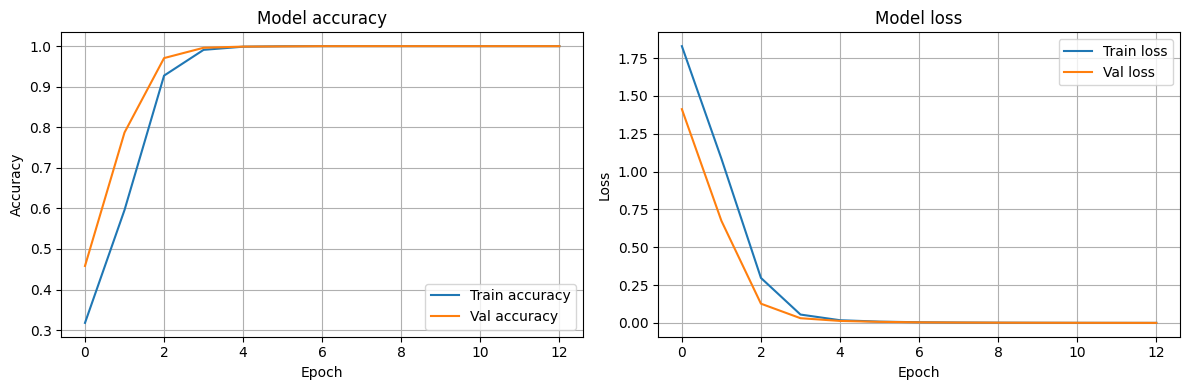

In [26]:
# -------------------- Training History Visualization --------------------
if 'history' in locals():
    # Plot accuracy
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train accuracy')
    plt.plot(history.history['val_accuracy'], label='Val accuracy')
    plt.title('Model accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    # Plot loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train loss')
    plt.plot(history.history['val_loss'], label='Val loss')
    plt.title('Model loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()
else:
    print("Training history variable not found")

The training was configured for a maximum of 50 epochs only to establish an upper bound. In practice, the `EarlyStopping` callback (configured with a patience of 3 epochs) halted the training at epoch 13, restoring the best weights which were recorded at epoch 10.

Throughout the training, the model demonstrated a distinctive convergence pattern:
*   **Accuracy:** In the very first epochs, the accuracy starts relatively low. This is a direct consequence of the masking strategy: since the metric excludes the easy-to-predict padding tokens and focuses solely on the meaningful operators and identifiers, the score honestly reflects the initial difficulty of the task. However, the learning curve is extremely steep; as soon as the attention mechanism aligns, performance skyrockets, reaching near-perfect accuracy starting from as early as epoch 8. The tight overlap between training and validation curves thereafter confirms the model has learned the generalizable rules of the grammar, not just memorized samples.
*   **Loss:** The loss plot exhibits a classic **"L-shaped" convergence**, dropping vertically in the initial epochs and flattening out at extremely low values. This confirms the model is highly confident in its predictions.

These metrics suggest that the network capacity is well-sized for the problem complexity and that the attention mechanism effectively resolves the structural ambiguities without manual feature engineering.

In [6]:
# --------------------- Load pretrained weights --------------------
FILE_ID_DRIVE = '1T2LNzgIWBMJgnuC5vrChoOKqVn_yah4s'
url = f'https://drive.google.com/uc?id={FILE_ID_DRIVE}'
weight_file = 'best_model.keras'

# Download weights if not present
if not os.path.exists(weight_file):
    print(f"File {weight_file} not found locally. Downloading from Google Drive...")
    try:
        gdown.download(url, weight_file, quiet=False)
    except Exception as e:
        print(f"Error downloading weights: {e}\n")

# Load weights if file exists
if os.path.exists(weight_file):
    print(f"Loading weights from {weight_file}...")
    try:
        # Load weights into the architecture defined above
        model.load_weights(weight_file)
        print("SUCCESS: Weights loaded. You can skip training and run tests directly.")
    except Exception as e:
        print(f"Error loading weights: {e}")
else:
    print("WARNING: Weight file not found. You must run model.fit() to train the model.")

File best_model.keras not found locally. Downloading from Google Drive...


Downloading...
From: https://drive.google.com/uc?id=1T2LNzgIWBMJgnuC5vrChoOKqVn_yah4s
To: <local-project>/best_model.keras
100%|██████████| 8.12M/8.12M [00:00<00:00, 40.3MB/s]

Loading weights from best_model.keras...
SUCCESS: Weights loaded. You can skip training and run tests directly.


# Evaluation

We shall evaluate a generated item y_pred using "prefix accuracy", the lenght of
the initial prefix of y_pred matching the ground true y_true. This will be divided by the maximum length of y_true and y_pred (up to EOS), so that a perfect match has score 1.

* It's more informative than exact match (which is often 0)

* It’s tighter than edit distance: focuses on generation flow

* Captures where the model starts to make errors



In [7]:
def prefix_accuracy_single(y_true, y_pred, id_to_token, eos_id=EOS_ID, verbose=False):
    t_str = decode_sequence(y_true, id_to_token).split(' EOS')[0]
    p_str = decode_sequence(y_pred, id_to_token).split(' EOS')[0]
    t_tokens = t_str.strip().split()
    p_tokens = p_str.strip().split()
    print(len(p_tokens))
    max_len = max(len(t_tokens), len(p_tokens))
    n = min(len(t_tokens), len(p_tokens))
    match_len = 0
    while match_len < n and t_tokens[match_len] == p_tokens[match_len]:
        match_len += 1
    score = match_len / max_len if max_len>0 else 0
    if verbose:
        print("TARGET :", ' '.join(t_tokens))
        print("PREDICT:", ' '.join(p_tokens))
        print(f"PREFIX MATCH: {match_len}/{len(t_tokens)} → {score:.2f}")

    return score

In [28]:
#example
i = np.random.randint(10000)
expected = np.copy(Y_train[i])
generated = np.copy(Y_train[i])
expr_len = np.where(generated==EOS_ID)[0][0]
j = np.random.randint(expr_len)
generated[j] = EOS_ID #making shorter
prefix_accuracy_single(expected,generated,id_to_token,verbose=True)

20
TARGET : d c + a c + / e f + f f + - e d / c d + * * +
PREDICT: d c + a c + / e f + f f + - e d / c d +
PREFIX MATCH: 20/23 → 0.87


0.8695652173913043

Since I employed an encoder-decoder architecture, generation during inference differs from training. I cannot rely on teacher forcing (feeding the known truth); instead, the model must function **autoregressively**, creating its own context on the fly.

The following function implements this loop: the encoder processes the input once, while the decoder generates the translation token-by-token, using its own previous prediction as the input for the next step until `EOS` is reached.

In [8]:
# -------------------- Autoregressive Decoding (w/ Attention) --------------------
def autoregressive_decode(model, input_seq):
    # Encode input sequence
    enc_results = model.encoder_inference.predict(np.expand_dims(input_seq, 0), verbose=0)
    enc_outs, states_value = enc_results[0], enc_results[1:]

    # Initialize decoder with SOS token
    target_seq = np.array([[SOS_ID]])
    decoded_sentence = [SOS_ID]

    # Decoding loop
    while True:
        # Predict next token and update states
        dec_results = model.decoder_inference.predict([target_seq, enc_outs] + states_value, verbose=0)
        output_tokens, states_value = dec_results[0], dec_results[1:]

        # Greedy selection
        sampled_token = np.argmax(output_tokens[0, -1, :])
        decoded_sentence.append(sampled_token)

        # Stop conditions
        if sampled_token == EOS_ID or len(decoded_sentence) > MAX_LEN:
            break

        # Update input
        target_seq[0, 0] = sampled_token

    return np.array(decoded_sentence)

Now that the autoregressive inference pipeline is defined, I proceed to quantitatively validate the model.

To ensure the results are robust and not subject to variance from a single random batch, I perform the evaluation over 10 independent rounds. In each round, I generate a fresh test set of 30 expressions, calculate the prefix accuracy for each, and finally report the aggregate **mean accuracy** and **standard deviation**.

In [9]:
def test(no=30,rounds=10):
  rscores =[]
  for i in range(rounds):
    print("round=",i)
    X_test, Y_test = generate_dataset(no)
    scores = []
    for j in range(no):
      encoder_input=X_test[j]
      generated = autoregressive_decode(model, encoder_input)[1:] #remove SOS
      scores.append(prefix_accuracy_single(Y_test[j], generated, id_to_token))
    rscores.append(np.mean(scores))
  return np.mean(rscores),np.std(rscores)

res, std = test(30,10)
print("score=",res,"std=",std)

round= 0
19
23
15
15
7
21
17
21
17
21
21
15
15
19
5
11
15
21
25
15
25
23
23
31
17
11
13
23
15
27
round= 1
25
27
17
19
25
21
17
11
23
15
15
17
19
7
27
23
17
13
29
23
11
23
13
13
17
19
13
9
3
23
round= 2
25
23
5
15
25
15
29
23
27
19
21
25
15
11
19
29
19
21
15
17
19
19
19
19
7
17
31
13
23
13
round= 3
19
13
13
21
25
9
7
23
15
21
15
19
11
19
21
11
15
19
5
13
5
13
17
9
19
25
21
15
23
13
round= 4
13
11
25
9
9
29
15
13
19
25
11
23
21
19
19
21
27
21
23
5
7
13
11
5
25
19
17
13
19
7
round= 5
3
19
21
21
23
15
7
13
23
11
13
5
15
23
19
25
21
23
9
15
29
13
13
29
27
23
17
27
23
7
round= 6
31
31
19
11
27
9
19
21
11
19
15
5
17
17
11
11
11
19
9
7
9
25
9
23
29
13
9
17
21
13
round= 7
27
23
9
23
25
15
13
25
19
15
11
11
17
7
23
9
25
13
25
3
25
23
23
15
19
11
7
17
17
5
round= 8
23
13
21
15
19
13
27
13
11
23
27
21
21
19
23
15
15
21
13
15
23
15
27
19
13
19
25
15
19
25
round= 9
27
15
11
23
29
15
11
7
11
19
19
15
11
31
21
25
21
23
13
19
25
15
25
11
25
5
13
17
25
21
score= 1.0 std= 0.0


## Conclusion

I evaluated the generator by ensuring that the model takes as input only the expression in infix format and returns its translation to postfix. Furthermore, since I employed an encoder-decoder model, the generation was performed autoregressively (via the `autoregressive_decode` function defined earlier), without any teacher forcing.

As shown in the final evaluation block, the model achieves a perfect score (average prefix accuracy: 1.0) with a standard deviation of 0.0 across all test rounds.

This confirms that the bi-LSTM encoder-decoder architecture with attention is more than capable of capturing the deterministic rules required to translate infix expressions to postfix notation for the given depth constraint ($D=4$).